In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('../data/real_estate_cleaned.csv', parse_dates=['date'])

features = ['sqft_living', 'sqft_lot', 'bedrooms', 'bathrooms', 'floors',
            'view', 'condition', 'waterfront', 'house_age',
            'has_basement', 'was_renovated']

X = df[features].copy()


X['sqft_living'] = np.log1p(X['sqft_living'])
X['sqft_lot'] = np.log1p(X['sqft_lot'])
X['log_price'] = np.log1p(df['price'])

In [2]:
from sklearn.preprocessing import StandardScaler

X_scaled = StandardScaler().fit_transform(X)

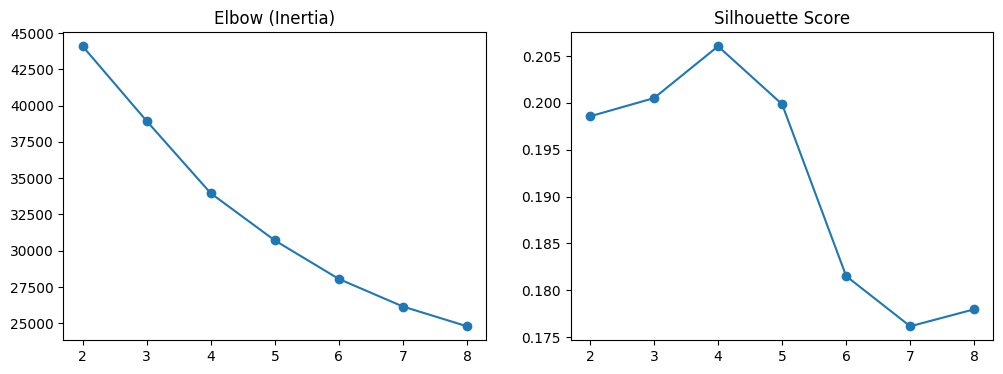

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_, sample_size=3000, random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertia, marker='o'); ax[0].set_title('Elbow (Inertia)')
ax[1].plot(ks, sil, marker='o');     ax[1].set_title('Silhouette Score')
plt.show()

In [4]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)
print(df['cluster'].value_counts().sort_index())

cluster
0    1676
1    1508
2    1327
3      30
Name: count, dtype: int64


In [5]:
profile = df.groupby('cluster').agg(
    n=('price', 'size'),
    median_price=('price', 'median'),
    median_area=('sqft_living', 'median'),
    median_lot=('sqft_lot', 'median'),
    bedrooms=('bedrooms', 'median'),
    bathrooms=('bathrooms', 'median'),
    avg_view=('view', 'mean'),
    median_age=('house_age', 'median'),
    waterfront_rate=('waterfront', 'mean'),
    basement_rate=('has_basement', 'mean'),
    renovated_rate=('was_renovated', 'mean'),
).round(2)
profile

,n,median_price,median_area,median_lot,bedrooms,bathrooms,avg_view,median_age,waterfront_rate,basement_rate,renovated_rate
cluster,,,,,,,,,,,
0,1676,537000.0,2430.0,7200.0,4.0,2.50,0.11,13.0,0.0,0.17,0.22
1,1508,320750.0,1310.0,7545.0,3.0,1.50,0.05,59.0,0.0,0.23,0.59
2,1327,580000.0,2290.0,8518.0,4.0,2.25,0.52,53.0,0.0,0.88,0.43
3,30,1072500.0,2835.0,18090.5,3.0,2.50,3.50,59.0,1.0,0.57,0.50


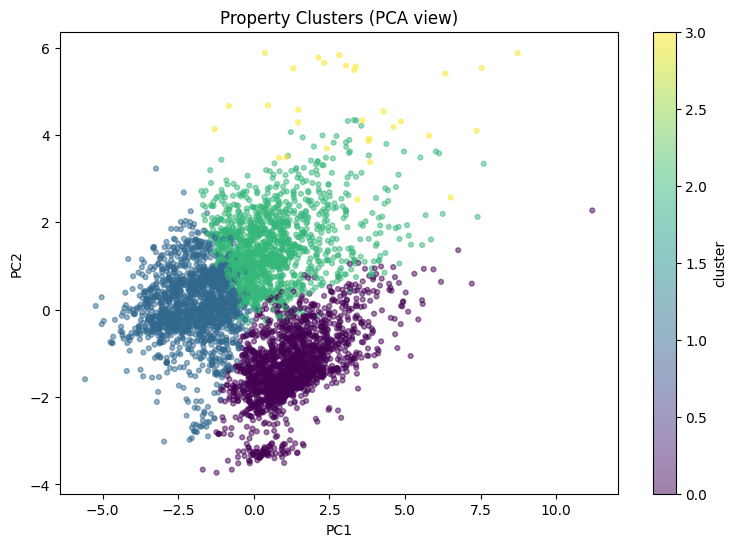

In [6]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))
plt.scatter(coords[:, 0], coords[:, 1], c=df['cluster'], cmap='viridis', alpha=0.5, s=12)
plt.title('Property Clusters (PCA view)')
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.colorbar(label='cluster')
plt.show()